# AQI Forecasting for Indian Cities — Exploratory Data Analysis

**Dataset:** Kaggle *Air Quality Data in India* — `city_day.csv` (daily pollutant readings + AQI from CPCB stations, 2015–2020).

**Goals of this notebook**
1. Understand the data's shape, coverage and missing values.
2. Choose which cities have enough data to model.
3. Decide how to handle missing values.
4. Find patterns (trend, seasonality, weekday, festivals, COVID) that should become **features** for the forecasting model.

In [1]:
import sys, pathlib
sys.path.append(str(pathlib.Path.cwd().parent))   # so we can import src/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import DIWALI_DATES, LOCKDOWN_START, MAX_INTERP_GAP, POLLUTANTS
from src.data import load_raw, city_coverage, select_cities, load_clean

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)
pd.set_option("display.width", 140)

## 1. Load and inspect

In [2]:
raw = load_raw()
print("Shape:", raw.shape)
print("Date range:", raw["Date"].min().date(), "→", raw["Date"].max().date())
print("Cities:", raw["City"].nunique())
raw.head()

Shape: (29531, 16)
Date range: 2015-01-01 → 2020-07-01
Cities: 26


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [3]:
raw.dtypes

City                  object
Date          datetime64[ns]
PM2.5                float64
PM10                 float64
NO                   float64
NO2                  float64
NOx                  float64
NH3                  float64
CO                   float64
SO2                  float64
O3                   float64
Benzene              float64
Toluene              float64
Xylene               float64
AQI                  float64
AQI_Bucket            object
dtype: object

In [4]:
raw.describe().T.round(1)

,count,mean,min,25%,50%,75%,max,std
Date,29531,2018-05-14 05:40:15.807118080,2015-01-01 00:00:00,2017-04-16 00:00:00,2018-08-05 00:00:00,2019-09-03 00:00:00,2020-07-01 00:00:00,NaN
PM2.5,24933.0,67.450578,0.04,28.82,48.57,80.59,949.99,64.661449
PM10,18391.0,118.127103,0.01,56.255,95.68,149.745,1000.0,90.60511
NO,25949.0,17.57473,0.02,5.63,9.89,19.95,390.68,22.785846
NO2,25946.0,28.560659,0.01,11.75,21.69,37.62,362.21,24.474746
NOx,25346.0,32.309123,0.0,12.82,23.52,40.1275,467.63,31.646011
NH3,19203.0,23.483476,0.01,8.58,15.85,30.02,352.89,25.684275
CO,27472.0,2.248598,0.0,0.51,0.89,1.45,175.81,6.962884
SO2,25677.0,14.531977,0.01,5.67,9.16,15.22,193.86,18.133775
O3,25509.0,34.49143,0.01,18.86,30.84,45.57,257.73,21.694928


**Conclusions**
- ~29.5k rows = one row per city per day, for 26 cities, from Jan 2015 to Jul 2020.
- Every pollutant column is numeric. `AQI_Bucket` is just the AQI category as text, so it can be recomputed from AQI and we won't use it as an input.
- AQI is heavily right-skewed: the median is far below the max (some days exceed 1000+). Error metrics will be dominated by the bad-pollution days.

## 2. Missing values

In [5]:
missing = raw.isna().mean().sort_values(ascending=False).mul(100).round(1)
missing.to_frame("% missing")

,% missing
Xylene,61.3
PM10,37.7
NH3,35.0
Toluene,27.2
Benzene,19.0
AQI,15.9
AQI_Bucket,15.9
PM2.5,15.6
NOx,14.2
O3,13.6


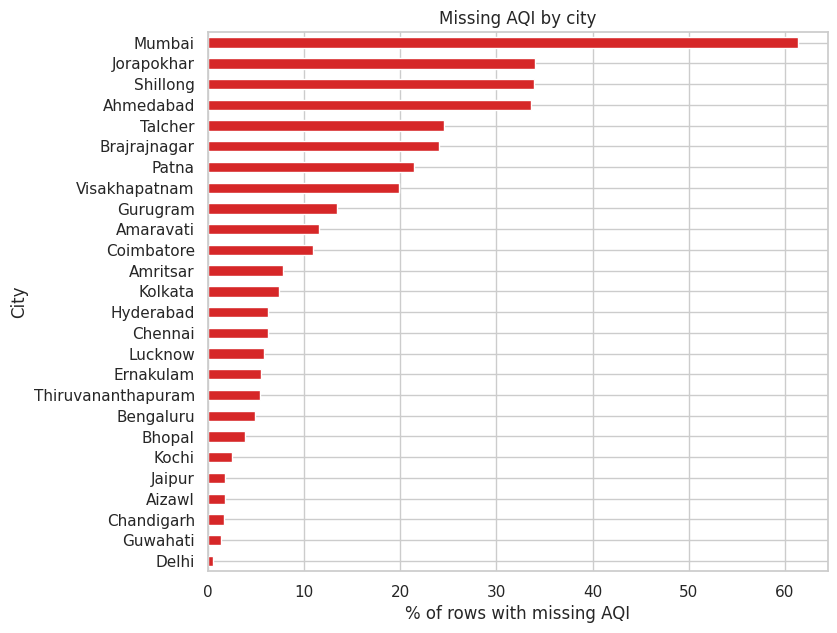

In [6]:
# % of rows with missing AQI, per city
miss_city = (raw.groupby("City")["AQI"].apply(lambda s: s.isna().mean() * 100)
                .sort_values())
miss_city.plot.barh(figsize=(8, 7), color="tab:red")
plt.xlabel("% of rows with missing AQI"); plt.title("Missing AQI by city"); plt.show()

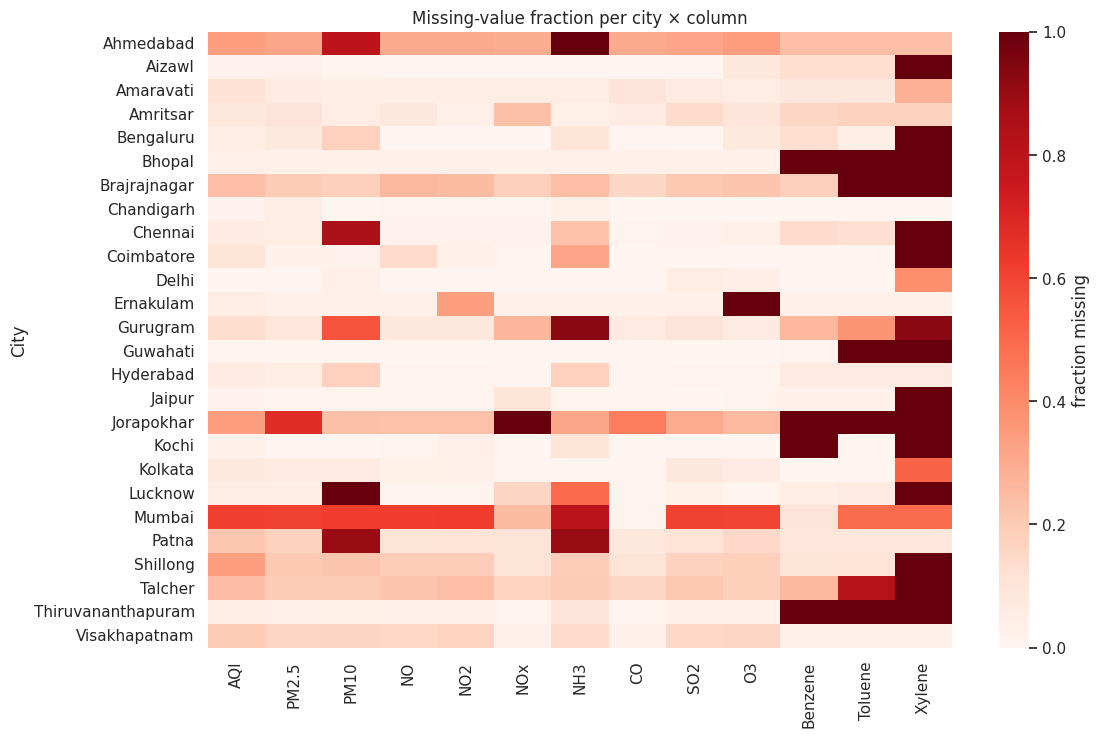

In [7]:
# Heatmap: fraction of missing values per pollutant per city
heat = raw.groupby("City")[["AQI"] + POLLUTANTS].apply(lambda g: g.isna().mean())
plt.figure(figsize=(12, 8))
sns.heatmap(heat, cmap="Reds", annot=False, cbar_kws={"label": "fraction missing"})
plt.title("Missing-value fraction per city × column"); plt.show()

**Conclusions**
- Xylene (61%), PM10 (38%) and NH3 (35%) are missing most often. Several stations never measured them.
- ~16% of AQI values are missing. That is our **target**, so rows with no AQI cannot be used for training.
- Missingness depends a lot on the city. Some cities (e.g. Mumbai, ~61% AQI missing) are too sparse to model reliably.
- Our forecasting model will mainly use **past AQI** (lags/rolling stats), not same-day pollutants. Those wouldn't be known in advance when forecasting the future. So pollutant gaps matter less than AQI gaps.

## 3. Choosing cities

In [8]:
cov = city_coverage(raw)
cov

,first_date,last_date,aqi_days,coverage
City,,,,
Delhi,2015-01-01,2020-07-01,1999,0.995
Bengaluru,2015-01-01,2020-07-01,1910,0.951
Lucknow,2015-01-01,2020-07-01,1893,0.942
Chennai,2015-01-01,2020-07-01,1884,0.938
Hyderabad,2015-01-04,2020-07-01,1880,0.937
Patna,2015-06-01,2020-07-01,1459,0.785
Gurugram,2015-11-27,2020-07-01,1453,0.865
Ahmedabad,2015-01-01,2020-07-01,1334,0.664
Visakhapatnam,2016-07-01,2020-07-01,1171,0.801


In [9]:
cities = select_cities(raw)
print(len(cities), "cities selected:", cities)

9 cities selected: ['Delhi', 'Bengaluru', 'Lucknow', 'Chennai', 'Hyderabad', 'Patna', 'Gurugram', 'Visakhapatnam', 'Amritsar']


**Selection rule:** a city needs **≥ 1100 days with AQI** (≈3 years, enough to see several winters) **and ≥ 75% coverage** over its own date range.

- This gives **9 cities**: Delhi, Bengaluru, Lucknow, Chennai, Hyderabad, Patna, Gurugram, Visakhapatnam, Amritsar. They cover north, south and east India, and both very polluted and fairly clean cities.
- Ahmedabad (66% coverage) and Mumbai (39%) are excluded despite having long date ranges: too many holes.
- Jaipur, Thiruvananthapuram, Kolkata etc. have good coverage but start in 2017–2018, so they have fewer winters.

## 4. Handling missing values

In [10]:
# How long are the AQI gaps in the selected cities?
rows = []
for c in cities:
    s = raw[raw.City == c].set_index("Date")["AQI"].asfreq("D")
    s = s.loc[s.first_valid_index():]
    na = s.isna()
    runs = na.groupby((~na).cumsum()).sum()
    runs = runs[runs > 0]
    rows.append({"City": c, "missing_days": int(na.sum()), "n_gaps": len(runs),
                 f"gaps_<= {MAX_INTERP_GAP}d": int((runs <= MAX_INTERP_GAP).sum()),
                 "longest_gap": int(runs.max()) if len(runs) else 0})
pd.DataFrame(rows).set_index("City")

,missing_days,n_gaps,gaps_<= 7d,longest_gap
City,,,,
Delhi,10,5,5,4
Bengaluru,20,8,8,7
Lucknow,37,13,12,17
Chennai,43,11,9,17
Hyderabad,40,12,11,20
Patna,275,49,46,171
Gurugram,169,51,47,22
Visakhapatnam,285,46,44,202
Amritsar,94,30,26,18


In [11]:
df = load_clean(cities)   # reindex to daily + time-interpolate gaps <= 7 days
print(df.shape)
print("AQI still missing after cleaning (inside long gaps):")
df.groupby("City")["AQI"].apply(lambda s: int(s.isna().sum()))

(15748, 15)
AQI still missing after cleaning (inside long gaps):


City
Amritsar          48
Bengaluru          0
Chennai           28
Delhi              0
Gurugram          60
Hyderabad         20
Lucknow           17
Patna            194
Visakhapatnam    212
Name: AQI, dtype: int64

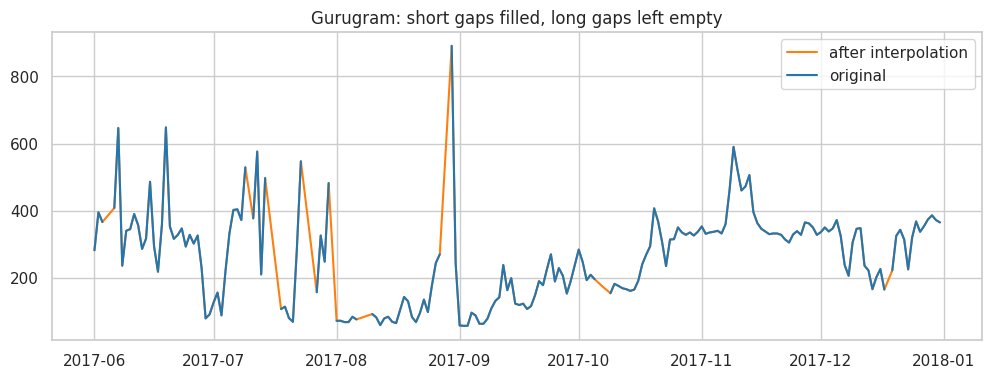

In [12]:
# Visual check: before vs after on a city with gaps
c = "Gurugram"
before = raw[raw.City == c].set_index("Date")["AQI"].asfreq("D").loc["2017-06":"2017-12"]
after = df[df.City == c].set_index("Date")["AQI"].loc["2017-06":"2017-12"]
plt.plot(after, color="tab:orange", label="after interpolation")
plt.plot(before, color="tab:blue", label="original")
plt.title(f"{c}: short gaps filled, long gaps left empty"); plt.legend(); plt.show()

**Why time-based interpolation (and only for short gaps)?**
- AQI is a **smooth time series**: today's value is close to yesterday's. Interpolating between neighbouring days is a reasonable guess for a gap of a few days.
- `method="time"` weights by actual time distance, so it stays correct even if dates are uneven.
- Gaps of **> 7 days are left empty.** Patna (171 days) and Visakhapatnam (202 days) each have one long outage. A straight line across 6 months would invent data and hide real seasonal swings.
- We **don't** fill with the global mean or forward-fill long stretches. The mean ignores season and city; forward-fill creates flat fake plateaus.
- We never extrapolate before the first or after the last real reading (`limit_area="inside"`).
- Remaining NaN rows are simply skipped when training. LightGBM can also handle NaN in lag features natively.

## 5. AQI trends per city

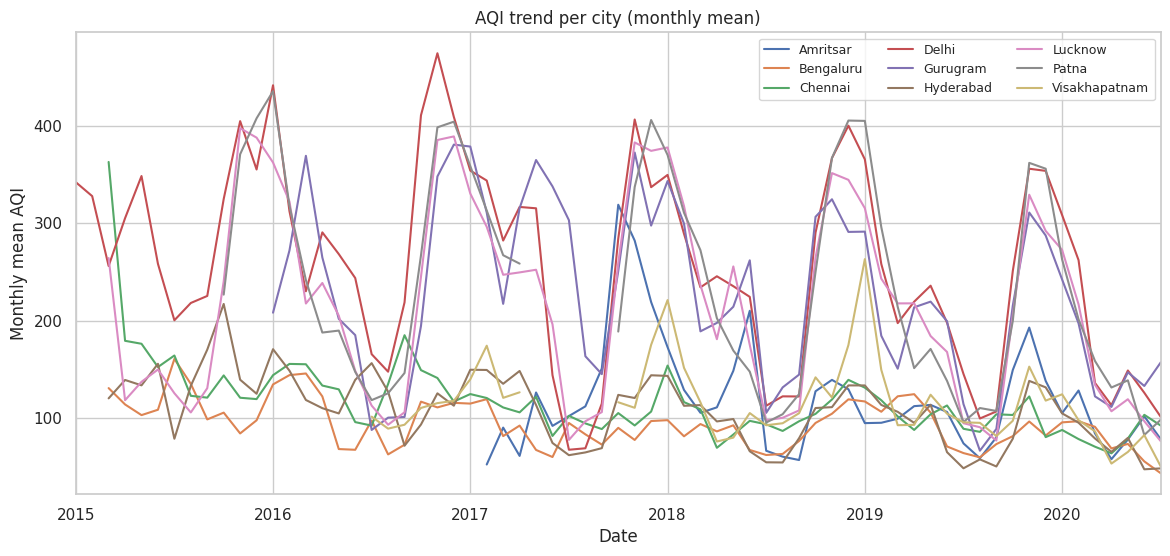

In [13]:
monthly = (df.set_index("Date").groupby("City")["AQI"].resample("MS").mean().unstack(0))
monthly.plot(figsize=(14, 6), linewidth=1.5)
plt.ylabel("Monthly mean AQI"); plt.title("AQI trend per city (monthly mean)")
plt.legend(ncol=3, fontsize=9); plt.show()

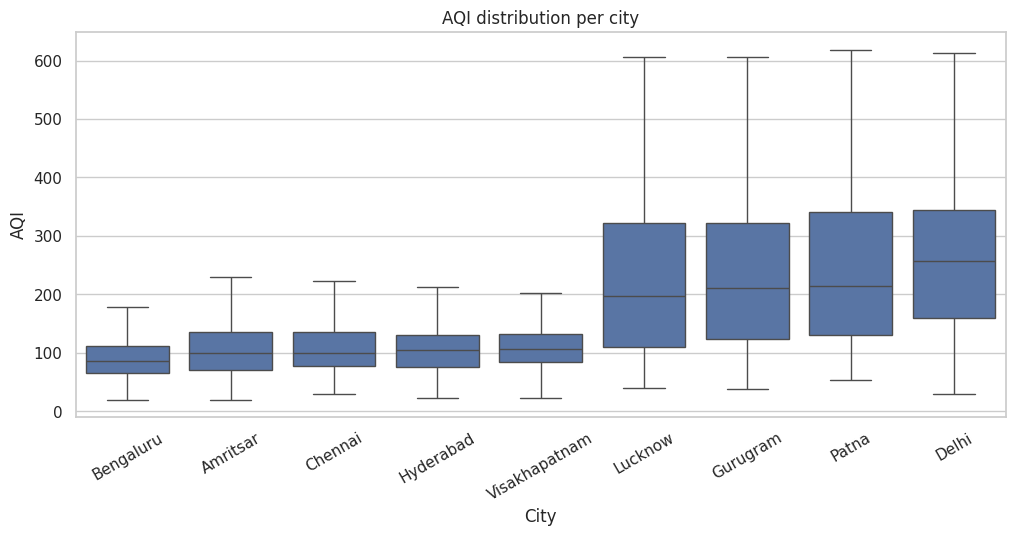

In [14]:
order = df.groupby("City")["AQI"].median().sort_values().index
plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x="City", y="AQI", order=order, showfliers=False)
plt.xticks(rotation=30); plt.title("AQI distribution per city"); plt.show()

**Conclusions**
- There are two clear groups. **North Indian cities** (Delhi ≈259, Patna ≈240, Gurugram ≈226, Lucknow ≈217 average AQI) are roughly **2× more polluted** than **southern/coastal cities** (Bengaluru ≈94, Hyderabad ≈109, Chennai ≈115).
- Every city shows a strong **yearly cycle**: peaks every winter and troughs every monsoon.
- Cities share the same seasonal shape but at different levels. That's a good argument for a **global model with city as a feature**: it learns the shared pattern once and the city-specific level separately.

## 6. Monthly / seasonal patterns

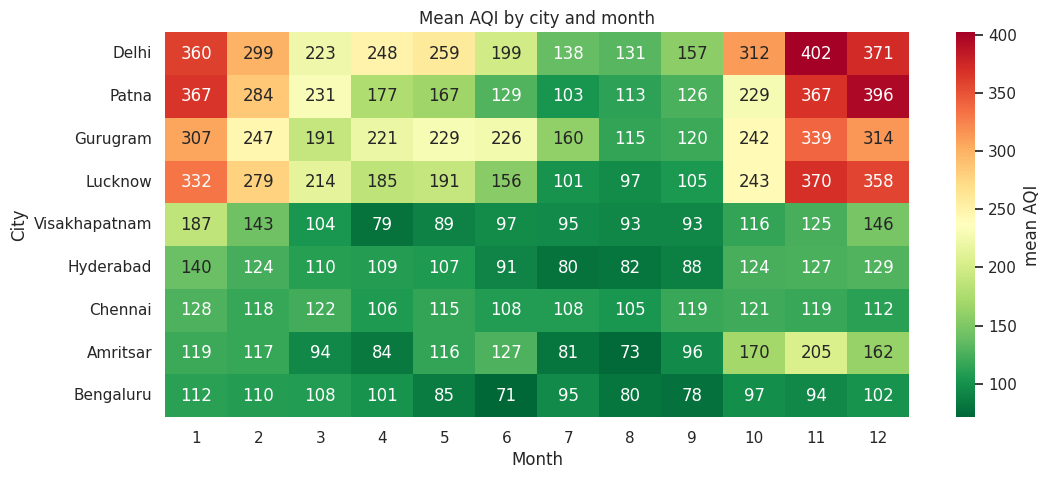

In [15]:
df["month"] = df["Date"].dt.month
piv = df.pivot_table(index="City", columns="month", values="AQI", aggfunc="mean")
plt.figure(figsize=(12, 5))
sns.heatmap(piv.loc[order[::-1]], cmap="RdYlGn_r", annot=True, fmt=".0f", cbar_kws={"label": "mean AQI"})
plt.title("Mean AQI by city and month"); plt.xlabel("Month"); plt.show()

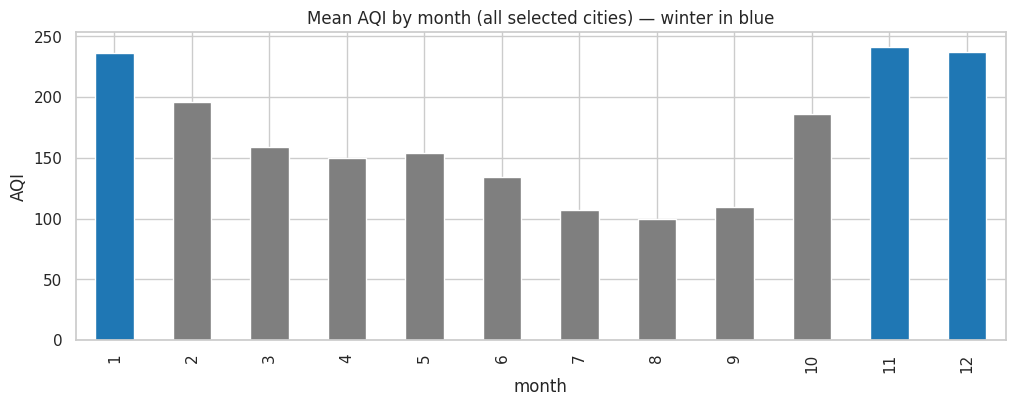

Winter (Nov–Jan) mean AQI: 239 | Monsoon (Jun–Aug): 115 | ratio 2.1x


In [16]:
m = df.groupby("month")["AQI"].mean()
m.plot.bar(color=["tab:blue" if x in (11, 12, 1) else "tab:gray" for x in m.index])
plt.title("Mean AQI by month (all selected cities) — winter in blue"); plt.ylabel("AQI"); plt.show()
winter = df[df.month.isin([11, 12, 1])]["AQI"].mean()
monsoon = df[df.month.isin([6, 7, 8])]["AQI"].mean()
print(f"Winter (Nov–Jan) mean AQI: {winter:.0f} | Monsoon (Jun–Aug): {monsoon:.0f} | ratio {winter/monsoon:.1f}x")

**Conclusions**
- **Winter (Nov–Jan) AQI is ~2× monsoon (Jun–Aug) AQI** (≈239 vs ≈115). The main reasons are temperature inversions that trap pollution near the ground, low wind, crop-stubble burning in Punjab/Haryana (Oct–Nov) and heating fires. In the monsoon, rain washes particles out of the air.
- The winter jump is far bigger in north India (Delhi/Gurugram/Lucknow/Patna). Southern cities vary much less.
- → Features: **month**, **day of year** and an **is_winter** flag (Nov–Jan).

## 7. Weekday effect

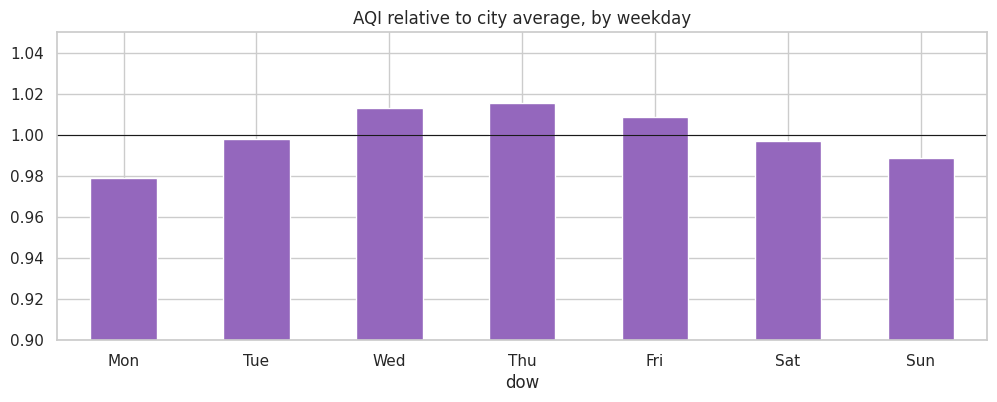

dow
0    0.979
1    0.998
2    1.013
3    1.016
4    1.009
5    0.997
6    0.989
Name: aqi_rel, dtype: float64

In [17]:
df["dow"] = df["Date"].dt.dayofweek
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
# Normalise by each city's mean so polluted cities don't dominate
df["aqi_rel"] = df["AQI"] / df.groupby("City")["AQI"].transform("mean")
w = df.groupby("dow")["aqi_rel"].mean()
ax = w.plot.bar(color="tab:purple"); ax.set_xticklabels(names, rotation=0)
plt.ylim(0.9, 1.05); plt.axhline(1, color="k", lw=0.8)
plt.title("AQI relative to city average, by weekday"); plt.show()
w.round(3)

**Conclusions**
- The weekday effect is **small, a few percent**: slightly higher Wed–Fri and lower Sun–Mon. That fits reduced traffic and industry at weekends (AQI is a 24-h average, so Sunday's drop shows up into Monday).
- It is tiny compared with the seasonal effect, but it's free to include, so we still add **day_of_week** as a feature.

## 8. Diwali / festival effect

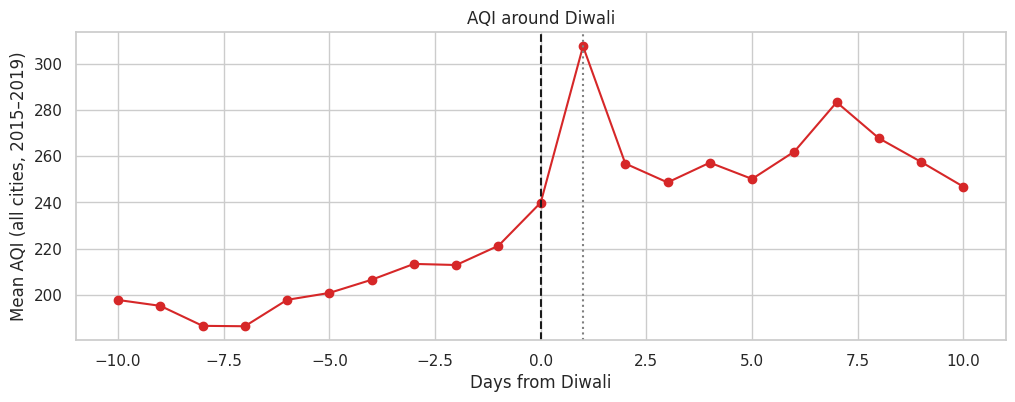

In [18]:
rows = []
for d in DIWALI_DATES[:5]:               # Diwali dates inside our 2015–2019 data
    d = pd.Timestamp(d)
    win = df[(df.Date >= d - pd.Timedelta(days=10)) & (df.Date <= d + pd.Timedelta(days=10))].copy()
    win["offset"] = (win["Date"] - d).dt.days
    win["year"] = d.year
    rows.append(win)
dw = pd.concat(rows)
avg = dw.groupby("offset")["AQI"].mean()
avg.plot(marker="o", color="tab:red")
plt.axvline(0, ls="--", color="k"); plt.axvline(1, ls=":", color="gray")
plt.xlabel("Days from Diwali"); plt.ylabel("Mean AQI (all cities, 2015–2019)")
plt.title("AQI around Diwali"); plt.show()

In [19]:
# Per-city spike: AQI on Diwali+1 vs mean of the week before
pre = dw[dw.offset.between(-7, -1)].groupby("City")["AQI"].mean()
post = dw[dw.offset == 1].groupby("City")["AQI"].mean()
((post / pre - 1) * 100).round(0).sort_values(ascending=False).to_frame("% jump on Diwali+1 vs prior week")

,% jump on Diwali+1 vs prior week
City,
Visakhapatnam,207.0
Amritsar,142.0
Hyderabad,62.0
Gurugram,55.0
Patna,54.0
Bengaluru,47.0
Lucknow,45.0
Delhi,25.0
Chennai,11.0


**Conclusions**
- Averaged over 5 Diwalis, AQI peaks on **the day after Diwali** (≈308 vs ≈210 in the week before, ~+45%). It's the next day because CPCB AQI is a **24-hour average** and the fireworks happen at night.
- The jump varies a lot by city: Visakhapatnam (+207%) and Amritsar (+142%) spike hardest; Delhi (+25%) and Chennai (+11%) less. Delhi is already very polluted before Diwali because of stubble smoke.
- Some of the rise is the normal Oct→Nov seasonal climb (stubble burning), which is why AQI stays high afterwards. The sharp one-day spike is the festival itself.
- → Features: **is_diwali** and **days_to_diwali** window flags (Diwali day, the day after, and a ±3-day window).

## 9. COVID-19 lockdown (2020)

In [20]:
lock = pd.Timestamp(LOCKDOWN_START)
def period_mean(start, end):
    return df[(df.Date >= start) & (df.Date <= end)].groupby("City")["AQI"].mean()

y20 = period_mean("2020-03-25", "2020-05-31")
y19 = period_mean("2019-03-25", "2019-05-31")
comp = pd.DataFrame({"2019 (same period)": y19, "2020 lockdown": y20})
comp["% change"] = ((comp.iloc[:, 1] / comp.iloc[:, 0] - 1) * 100).round(0)
comp.sort_values("% change").round(0)

,2019 (same period),2020 lockdown,% change
City,,,
Lucknow,205.0,112.0,-45.0
Delhi,226.0,125.0,-44.0
Gurugram,212.0,123.0,-42.0
Visakhapatnam,107.0,62.0,-42.0
Amritsar,115.0,67.0,-41.0
Bengaluru,116.0,71.0,-39.0
Hyderabad,106.0,72.0,-32.0
Chennai,94.0,70.0,-26.0
Patna,164.0,134.0,-18.0


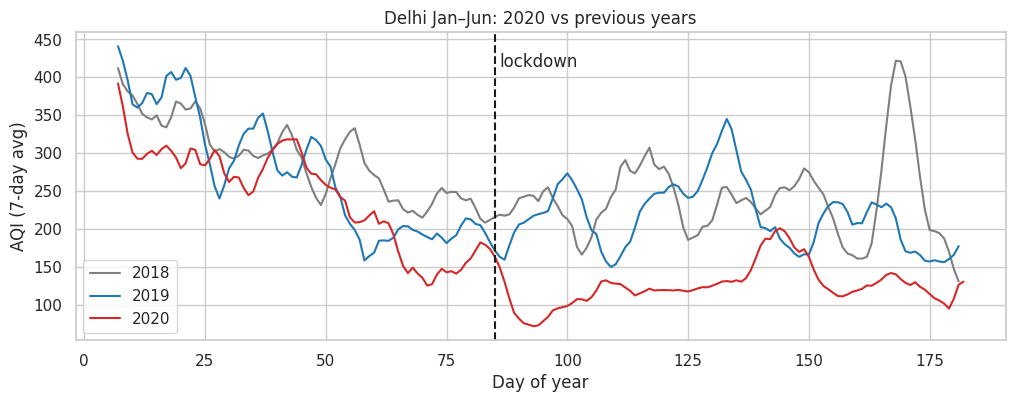

In [21]:
delhi = df[df.City == "Delhi"].set_index("Date")["AQI"]
fig, ax = plt.subplots(figsize=(12, 4))
for yr, col in [(2018, "tab:gray"), (2019, "tab:blue"), (2020, "tab:red")]:
    s = delhi.loc[f"{yr}-01-01":f"{yr}-06-30"].rolling(7).mean()
    ax.plot(s.index.dayofyear, s.values, label=str(yr), color=col)
ax.axvline(lock.dayofyear, ls="--", color="k"); ax.text(lock.dayofyear + 1, ax.get_ylim()[1] * 0.9, "lockdown")
ax.set_xlabel("Day of year"); ax.set_ylabel("AQI (7-day avg)"); ax.set_title("Delhi Jan–Jun: 2020 vs previous years")
ax.legend(); plt.show()

**Conclusions**
- During the lockdown (25 Mar – 31 May 2020), AQI was on average **~38% lower** than the same weeks of 2019. Lucknow, Delhi, Gurugram, Visakhapatnam and Amritsar fell by 40%+.
- This is a natural experiment: traffic and industry are a large share of pollution.
- **Modelling implication:** 2020 is unusual. Our test period will include it, so we need features that react quickly (short lags like lag_1 and lag_2). Models that only learned "typical spring" levels will be biased. We **don't** add a lockdown feature, because we couldn't know it in advance for future dates.

## 10. Pollutants vs AQI

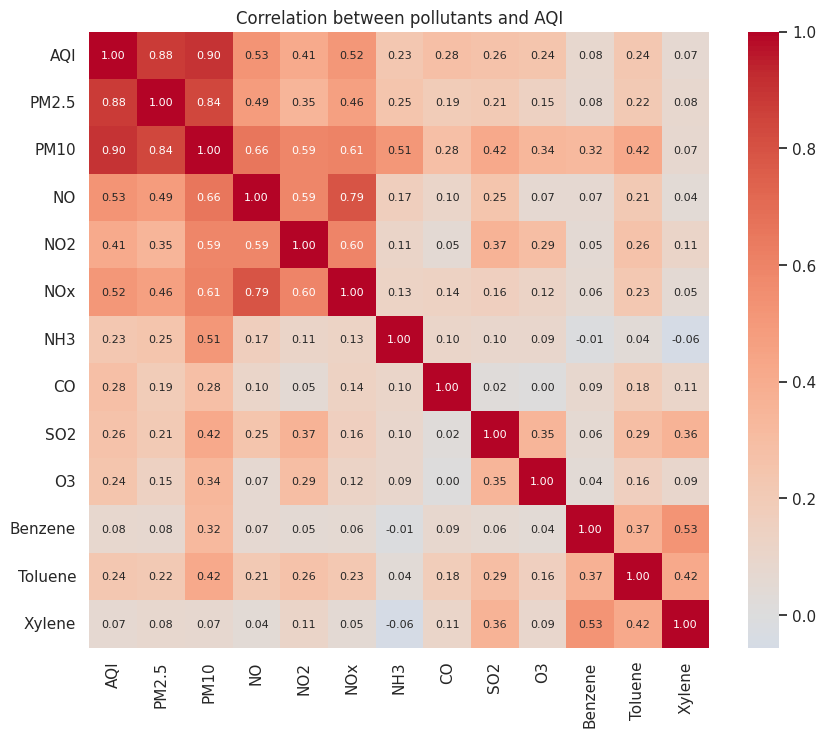

,corr with AQI
PM10,0.90
PM2.5,0.88
NO,0.53
NOx,0.52
NO2,0.41
CO,0.28
SO2,0.26
O3,0.24
Toluene,0.24
NH3,0.23


In [22]:
corr = df[["AQI"] + POLLUTANTS].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title("Correlation between pollutants and AQI"); plt.show()
corr["AQI"].drop("AQI").sort_values(ascending=False).round(2).to_frame("corr with AQI")

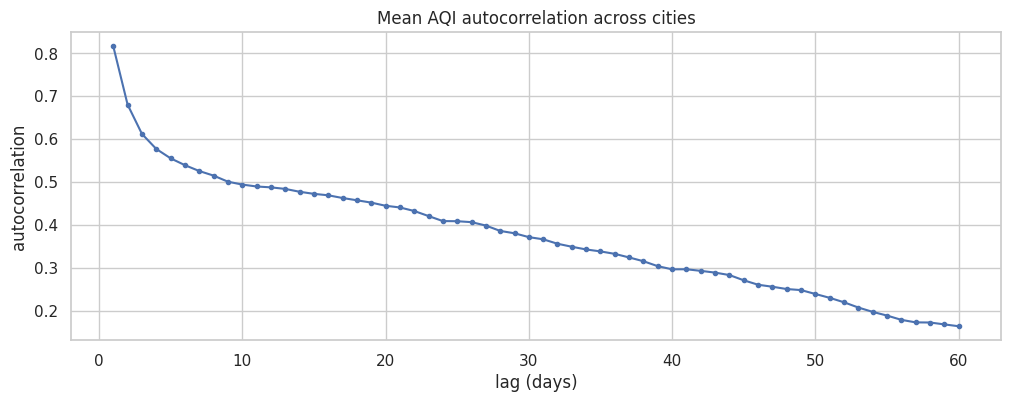

1     0.82
2     0.68
3     0.61
7     0.53
14    0.48
30    0.37
dtype: float64

In [23]:
# AQI autocorrelation: how strongly does today relate to past days?
from pandas.plotting import autocorrelation_plot
lags = range(1, 61)
ac = pd.DataFrame({c: [df[df.City == c].set_index("Date")["AQI"].autocorr(l) for l in lags] for c in cities}, index=lags)
ac.mean(axis=1).plot(marker=".")
plt.xlabel("lag (days)"); plt.ylabel("autocorrelation"); plt.title("Mean AQI autocorrelation across cities"); plt.show()
ac.mean(axis=1).loc[[1, 2, 3, 7, 14, 30]].round(2)

**Conclusions**
- **PM10 (0.90) and PM2.5 (0.88)** correlate most strongly with AQI. In Indian cities, AQI is almost always driven by particulate matter (CPCB AQI = the worst sub-index of all pollutants).
- NO/NOx (~0.5) are moderate (traffic). O3, SO2 and CO are weaker.
- **AQI is strongly autocorrelated:** 0.82 at lag 1, 0.53 at lag 7, and still 0.37 at lag 30. This justifies the **lag (1, 2, 3, 7, 14, 30) and rolling-mean** features.
- We will **not** feed same-day pollutants into the 7-day-ahead model, because we won't know next week's PM2.5 when forecasting. Past AQI already contains that information.

## 11. Summary — what EDA tells the model

| Finding | Modelling decision |
|---|---|
| 9 cities have good coverage | Model only those 9 |
| Short gaps are common, a few long outages | Time-interpolate gaps ≤ 7 days, drop the rest |
| Strong autocorrelation | Lag features 1, 2, 3, 7, 14, 30 + rolling mean/std 7, 14, 30 |
| Strong winter seasonality (~2×) | month, day_of_year, is_winter |
| Small weekday effect | day_of_week |
| Diwali spike (+45% next day) | Diwali flags |
| Different levels per city, same shape | One **global LightGBM** with city as a categorical feature |
| 2020 lockdown shock | Time-based validation that includes 2020 to test robustness |